[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/12-data-annotation-and-rlhf/notebooks/03-dpo-loss-demo.ipynb)

# 03 - The DPO loss on toy numbers (and on a real model)

**Goal:** understand **Direct Preference Optimization (DPO)** by computing its loss with your own hands, in PyTorch, and watching it change a toy model.

**Words you need**
- **Policy** - the model being trained.
- **Reference model** - a frozen copy of the starting model (usually the SFT model); it never changes.
- **Log-probability** - the logarithm of a probability. Always <= 0; closer to 0 means "more likely".
- **beta (β)** - a dial: how strongly to stay close to the reference.

DPO loss for one pair:
`loss = -log sigmoid( beta * [ (logp_policy(chosen) - logp_ref(chosen)) - (logp_policy(rejected) - logp_ref(rejected)) ] )`

## Step 1 - Imports

In [1]:
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0)
print("ok")

ok


## Step 2 - The toy numbers from concepts.md, by hand with `math`

We use plain Python first so nothing is hidden.

In [2]:
beta = 0.1
pol_c, ref_c = -12.0, -14.0      # chosen: policy likes it more than the reference does
pol_r, ref_r = -15.0, -13.0      # rejected: policy likes it less than the reference does

chosen_reward = pol_c - ref_c    # "implicit reward" of the chosen answer
rejected_reward = pol_r - ref_r
margin = chosen_reward - rejected_reward
sigmoid = 1 / (1 + math.exp(-beta * margin))
loss = -math.log(sigmoid)
print(f"implicit rewards: chosen {chosen_reward:+.1f}, rejected {rejected_reward:+.1f}")
print(f"margin {margin}, beta*margin {beta*margin:.2f}, sigmoid {sigmoid:.3f}, loss {loss:.3f}")
print(f"loss if policy == reference: {-math.log(0.5):.3f}")

implicit rewards: chosen +2.0, rejected -2.0
margin 4.0, beta*margin 0.40, sigmoid 0.599, loss 0.513
loss if policy == reference: 0.693


## Step 3 - The same thing as a PyTorch function

This is essentially the core of what libraries like TRL compute, for a whole **batch** (group) of pairs at once. `F.logsigmoid` is the safe version of `log(sigmoid(x))`.

In [3]:
def dpo_loss(pol_chosen, pol_rejected, ref_chosen, ref_rejected, beta=0.1):
    """All inputs are tensors of summed log-probabilities, one value per pair."""
    chosen_rewards = beta * (pol_chosen - ref_chosen)
    rejected_rewards = beta * (pol_rejected - ref_rejected)
    losses = -F.logsigmoid(chosen_rewards - rejected_rewards)
    return losses.mean(), chosen_rewards, rejected_rewards

pc = torch.tensor([-12.0], requires_grad=True)   # requires_grad: track gradients for this value
pr = torch.tensor([-15.0], requires_grad=True)
loss, cr, rr = dpo_loss(pc, pr, torch.tensor([-14.0]), torch.tensor([-13.0]))
print("loss:", round(loss.item(), 4))

loss: 0.513


## Step 4 - Which way does training push?

`loss.backward()` computes the **gradient** - how the loss changes if we nudge each input. An optimizer moves *against* the gradient. A negative gradient on the chosen log-prob means "raise the chosen answer's probability"; a positive one on the rejected log-prob means "lower it".

In [4]:
loss.backward()
print("gradient wrt chosen log-prob  :", round(pc.grad.item(), 4), "-> increase chosen")
print("gradient wrt rejected log-prob:", round(pr.grad.item(), 4), "-> decrease rejected")

gradient wrt chosen log-prob  : -0.0401 -> increase chosen
gradient wrt rejected log-prob: 0.0401 -> decrease rejected


## Step 5 - How beta changes the loss curve

We plot loss against the margin (how much more the policy prefers chosen over rejected, relative to the reference) for three betas. Small beta = a gentle curve that needs a large margin before the loss stops pushing. Large beta = steep curve; satisfied with small changes, so the policy stays near the reference.

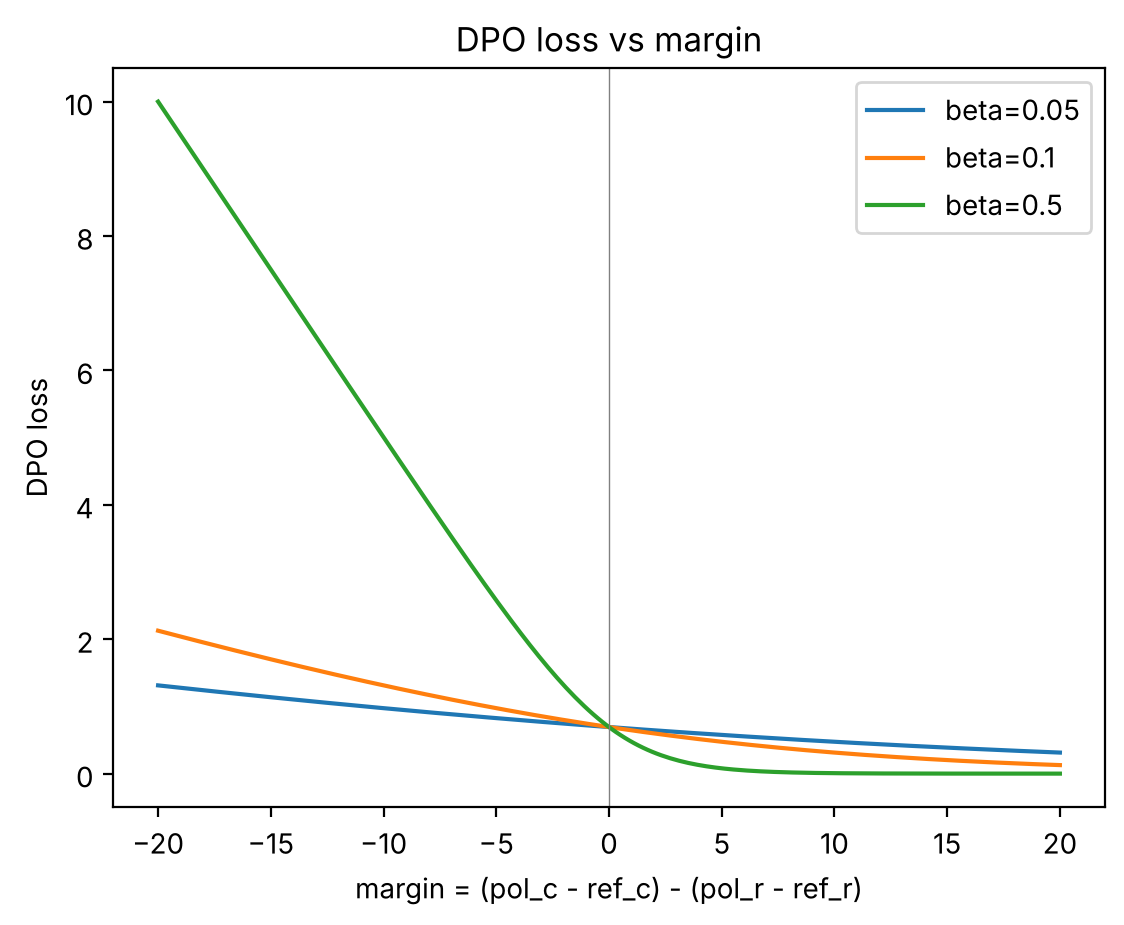

In [5]:
margins = torch.linspace(-20, 20, 200)
for b in [0.05, 0.1, 0.5]:
    plt.plot(margins, -F.logsigmoid(b * margins), label=f"beta={b}")
plt.axvline(0, color="grey", lw=0.5)
plt.xlabel("margin = (pol_c - ref_c) - (pol_r - ref_r)"); plt.ylabel("DPO loss"); plt.legend()
plt.title("DPO loss vs margin"); plt.show()

## Step 6 - A toy policy that we actually train with DPO

Imagine one prompt with four possible answers: A (great), B (good), C (meh), D (bad). The policy is just four numbers (**logits**, scores turned into probabilities by **softmax**). Humans gave preference pairs: A > D, A > C, B > D, B > C.

We train with DPO and watch the probabilities move. The reference stays frozen at the starting point.

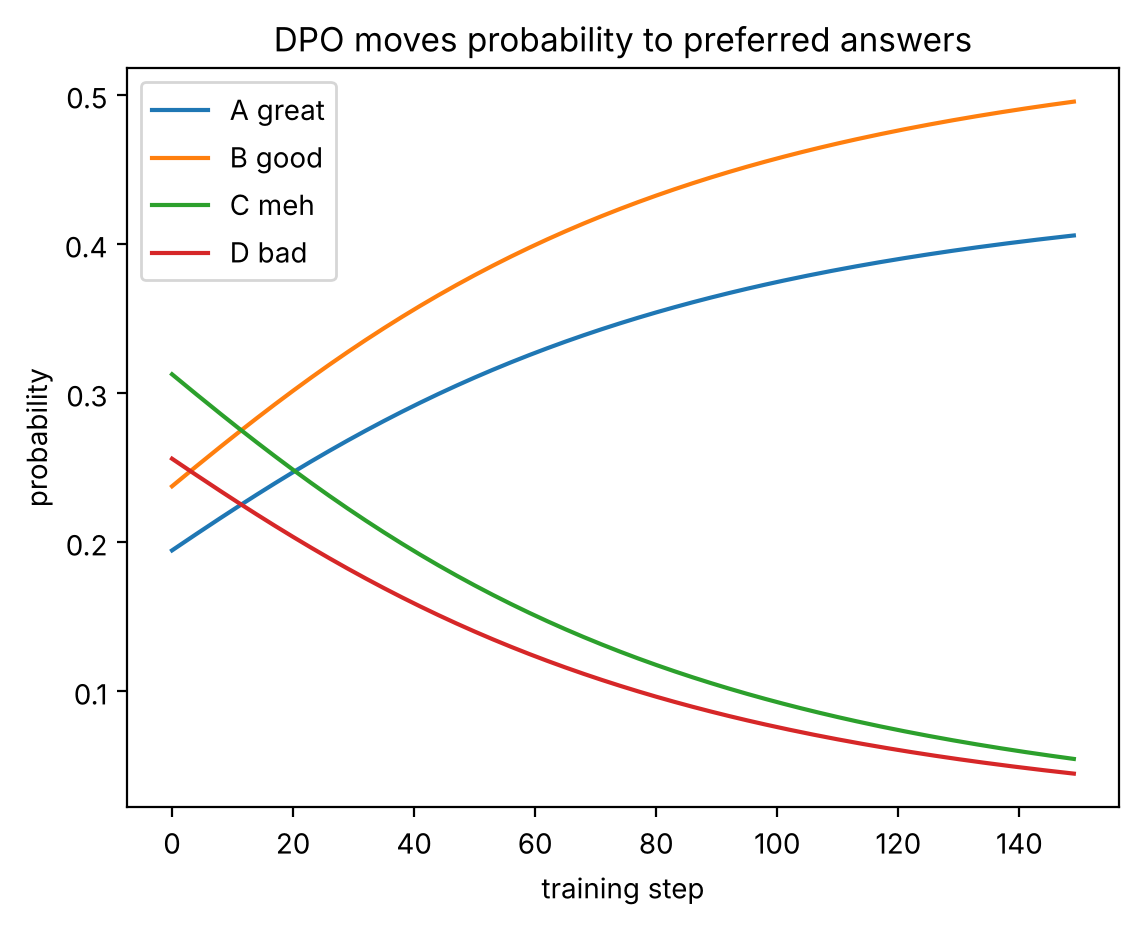

start: [0.19, 0.23, 0.32, 0.26]
end  : [0.41, 0.5, 0.05, 0.04]


In [6]:
answers = ["A great", "B good", "C meh", "D bad"]
prefs = [(0, 3), (0, 2), (1, 3), (1, 2)]        # (chosen index, rejected index)
start_logits = torch.tensor([0.0, 0.2, 0.5, 0.3])  # starting policy slightly prefers C and D!

def train_dpo(beta, steps=150, lr=0.1):
    logits = start_logits.clone().requires_grad_(True)
    ref_logp = F.log_softmax(start_logits, dim=0)          # frozen reference
    opt = torch.optim.SGD([logits], lr=lr)
    probs_over_time = []
    for _ in range(steps):
        logp = F.log_softmax(logits, dim=0)
        c = torch.tensor([i for i, _ in prefs]); r = torch.tensor([j for _, j in prefs])
        loss, _, _ = dpo_loss(logp[c], logp[r], ref_logp[c], ref_logp[r], beta)
        opt.zero_grad(); loss.backward(); opt.step()
        probs_over_time.append(F.softmax(logits, dim=0).detach())
    return torch.stack(probs_over_time)

hist = train_dpo(beta=0.5)
for k, name in enumerate(answers):
    plt.plot(hist[:, k], label=name)
plt.xlabel("training step"); plt.ylabel("probability"); plt.legend(); plt.title("DPO moves probability to preferred answers")
plt.show()
print("start:", [round(p, 2) for p in F.softmax(start_logits, 0).tolist()])
print("end  :", [round(p, 2) for p in hist[-1].tolist()])

## Step 7 - Beta controls drift from the reference

**KL divergence** measures how far the final policy has moved from the reference distribution (0 = not moved at all).

Look back at the plot in Step 5: the loss flattens once `beta x margin` is a few units. So a *large* beta is "satisfied" by a *small* margin and stops pushing early, while a *small* beta keeps pushing until the margin is large. To compare fairly we scale the learning rate by `1/beta` so every run starts with the same push. Expect: bigger beta -> smaller KL -> policy stays closer to the reference. In practice beta is tuned; 0.1 is a common starting value.

In [7]:
ref_p = F.softmax(start_logits, 0)
for b in [0.1, 0.5, 2.0]:
    final = train_dpo(beta=b, steps=300, lr=0.05 / b)[-1]
    kl = torch.sum(final * (final.log() - ref_p.log())).item()
    print(f"beta={b:<4}  final probs={[round(x, 2) for x in final.tolist()]}  KL from reference={kl:.3f}")

beta=0.1   final probs=[0.45, 0.55, 0.0, 0.0]  KL from reference=0.836
beta=0.5   final probs=[0.44, 0.53, 0.02, 0.01]  KL from reference=0.711


beta=2.0   final probs=[0.36, 0.44, 0.11, 0.09]  KL from reference=0.288


## Step 8 - Real log-probabilities from a real language model

In real DPO, `logp(answer)` is the **sum of the log-probabilities of each token** of the answer, given the prompt. A **token** is a word or piece of a word. We load a small chat model (`SmolLM2-135M-Instruct`, about 270 MB, downloads once from Hugging Face) and compute these numbers for a chosen and a rejected answer.

At the start of DPO training the policy *is* the reference, so the loss must be exactly `log(2) ≈ 0.693`. Let's check.

In [8]:
from transformers import AutoModelForCausalLM, AutoTokenizer
mid = "HuggingFaceTB/SmolLM2-135M-Instruct"
tok = AutoTokenizer.from_pretrained(mid)
model = AutoModelForCausalLM.from_pretrained(mid)
model.eval()

@torch.no_grad()
def answer_logprob(prompt, answer):
    """Sum of log-probs of the answer tokens, given the prompt (chat formatted)."""
    p_ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True,
                                    return_tensors="pt", return_dict=True)["input_ids"]
    a_ids = tok(answer, return_tensors="pt", add_special_tokens=False)["input_ids"]
    ids = torch.cat([p_ids, a_ids], dim=1)
    logits = model(ids).logits[:, :-1]                 # prediction for the NEXT token at each position
    logp = F.log_softmax(logits, dim=-1)
    targets = ids[:, 1:]
    token_logp = logp.gather(2, targets.unsqueeze(-1)).squeeze(-1)
    return token_logp[:, p_ids.shape[1] - 1:].sum().item()   # keep only the answer part

prompt = "What is the capital of France?"
chosen, rejected = "The capital of France is Paris.", "France does not have a capital."
lc, lr_ = answer_logprob(prompt, chosen), answer_logprob(prompt, rejected)
print(f"log p(chosen) = {lc:.2f}   log p(rejected) = {lr_:.2f}")
loss0, _, _ = dpo_loss(torch.tensor([lc]), torch.tensor([lr_]), torch.tensor([lc]), torch.tensor([lr_]))
print("DPO loss with policy == reference:", round(loss0.item(), 4), " (log 2 =", round(math.log(2), 4), ")")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 16633.63it/s]

log p(chosen) = -0.48   log p(rejected) = -17.88
DPO loss with policy == reference: 0.6931  (log 2 = 0.6931 )


## Step 9 - How you would run real DPO (not executed here)

On a GPU you would use Hugging Face **TRL**. The code below shows the shape of it; it is a markdown cell so this notebook stays fast on a CPU. Check the current TRL docs for exact arguments (as of late 2026, `DPOConfig` has `beta` and `max_length`).

```python
from datasets import Dataset
from trl import DPOConfig, DPOTrainer
data = Dataset.from_list([{"prompt": "...", "chosen": "...", "rejected": "..."}, ...])
args = DPOConfig(output_dir="dpo-out", beta=0.1, per_device_train_batch_size=2, max_steps=100)
trainer = DPOTrainer(model="your-sft-model", args=args, train_dataset=data, processing_class=tokenizer)
trainer.train()
```
If you pass no `ref_model`, TRL makes the frozen reference for you.

## What you learned

- DPO loss = -log sigmoid(beta x [implicit reward of chosen - implicit reward of rejected]).
- Its gradient raises the chosen answer and lowers the rejected one, relative to a frozen reference.
- beta controls how far the policy may drift.
- With a real model, log p(answer) = sum of token log-probs; at the start the loss is log 2.